# Analysis of Temporal and Spectral Consistency in Real and Synthetic EEG Data Using VAE

This notebook is a comprehensive implementation to process, analyze, and visualize EEG data. The primary focus of this code is on performing statistical feature extraction, and comparing real and synthetic EEG signals using various visualizations.                                             
These visualizations include statistical distributions, waveforms, power spectral densities (PSDs), and similarity heatmaps.                           
The goal is to evaluate how well the synthetic EEG data generated by the VAE compares with real EEG data based on several statistical properties.

In [1]:
# Importing Libraries

import os
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from scipy.stats import kurtosis, skew
import seaborn as sns
from scipy.signal import welch

# Library imports - use centralized implementations for data loading, metrics, and visualizations
from generative_eeg_augmentation.data.loader import load_all_preprocessed
from generative_eeg_augmentation.eval.eeg_metrics import compute_time_domain_features, compute_psd, EEG_BANDS
from generative_eeg_augmentation.plots.eeg_visualizations import (
    plot_statistical_comparison, 
    plot_waveforms, 
    plot_psd_comparison, 
    plot_similarity_heatmap,
    set_eeg_visualization_style
)

# Set visualization style
set_eeg_visualization_style()

In [2]:
# Load preprocessed EEG data using library's data loader
# This replaces the old Windows-specific path loading with portable library function

real_epochs, labels = load_all_preprocessed()
real_data = torch.tensor(real_epochs, dtype=torch.float32)

# Sampling frequency is 200 Hz (downsampled during preprocessing)
sfreq = 200

print(f"Loaded {len(real_epochs)} epochs from preprocessed dataset")
print(f"Data shape: {real_data.shape} (epochs, channels, timepoints)")
print(f"Sampling frequency: {sfreq} Hz")

Loaded preprocessed EEG data shape: (250, 63, 1001)
Loaded labels shape: (250, 2)
Loaded 250 epochs from preprocessed dataset
Data shape: torch.Size([250, 63, 1001]) (epochs, channels, timepoints)
Sampling frequency: 200 Hz


In [3]:
# Define the Variational Autoencoder Model (VAE)
# NOTE: This VAE uses a LINEAR encoder architecture, which differs from the library's 
# VAE (Conv1d encoder) in generative_eeg_augmentation.models.vae. This architecture
# was used for the original evaluation and is kept for consistency with stored results.

class VAE(nn.Module):
    def __init__(self, n_channels=63, latent_dim=100, target_signal_len=1001):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(n_channels * target_signal_len, 512),
            nn.ReLU(),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Linear(256, latent_dim) 
        )
        self.fc_mu = nn.Linear(latent_dim, latent_dim)
        self.fc_logvar = nn.Linear(latent_dim, latent_dim)
        self.decoder_input = nn.Linear(latent_dim, 256 * (target_signal_len // 8))
        self.decoder = nn.Sequential(
            nn.ConvTranspose1d(256, 128, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),
            nn.ConvTranspose1d(128, 64, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),
            nn.ConvTranspose1d(64, n_channels, kernel_size=4, stride=2, padding=1),
            nn.Tanh()
        )

    def encode(self, x):
        x = self.encoder(x.view(x.size(0), -1))
        mu, logvar = self.fc_mu(x), self.fc_logvar(x)
        return mu, logvar

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        x = self.decoder_input(z)
        x = x.view(x.size(0), 256, -1)
        return self.decoder(x)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar


vae_model = VAE(n_channels=63, latent_dim=100, target_signal_len=1001)
vae_model.eval()

print("VAE model loaded successfully.")

VAE model loaded successfully.


In [4]:
# Generate Synthetic EEG Data using VAE
def generate_synthetic_data(vae_model, num_samples=100, latent_dim=100, device="cpu"):
    z = torch.randn(num_samples, latent_dim).to(device)
    with torch.no_grad():
        synthetic_data = vae_model.decode(z)
    
    return synthetic_data.cpu().numpy()

In [5]:
# Generate synthetic EEG data to match the number of real samples
num_samples = min(len(real_data), 100)  # Use up to 100 samples for visualization
synthetic_data = generate_synthetic_data(vae_model, num_samples=num_samples)
print(f"Synthetic EEG data generated with shape: {synthetic_data.shape}")
print(f"Using {num_samples} samples from real data for comparison")

Synthetic EEG data generated with shape: (100, 63, 1000)
Using 100 samples from real data for comparison


### Statistical Features Extraction

In [6]:
# Statistical feature extraction using library function
# Note: compute_time_domain_features is imported from generative_eeg_augmentation.eval.eeg_metrics
# This replaces the inline definition with the centralized library implementation

In [7]:
# Compute time-domain features using library function
# Use subset of real data matching the synthetic data size
real_data_subset = real_data[:num_samples]

real_mean, real_var, real_kurt, real_skew = compute_time_domain_features(real_data_subset)
synthetic_mean, synthetic_var, synthetic_kurt, synthetic_skew = compute_time_domain_features(torch.tensor(synthetic_data))

print(f"Computed features for {num_samples} real and synthetic samples")

Computed features for 100 real and synthetic samples


In [8]:
# Statistical comparison and visualization
# Using library's plot_statistical_comparison function from generative_eeg_augmentation.plots
# The library function returns a matplotlib Figure object for flexible display

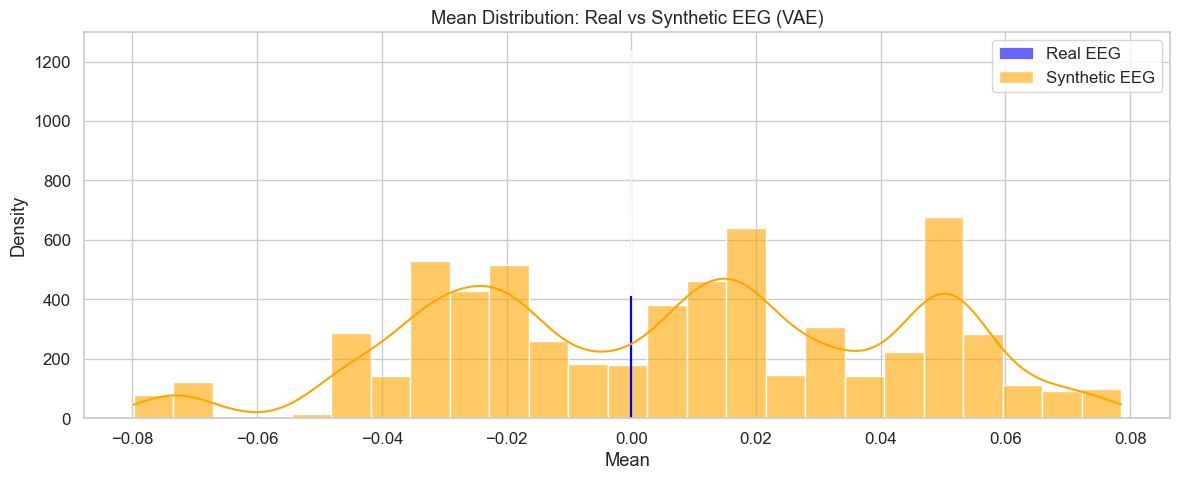

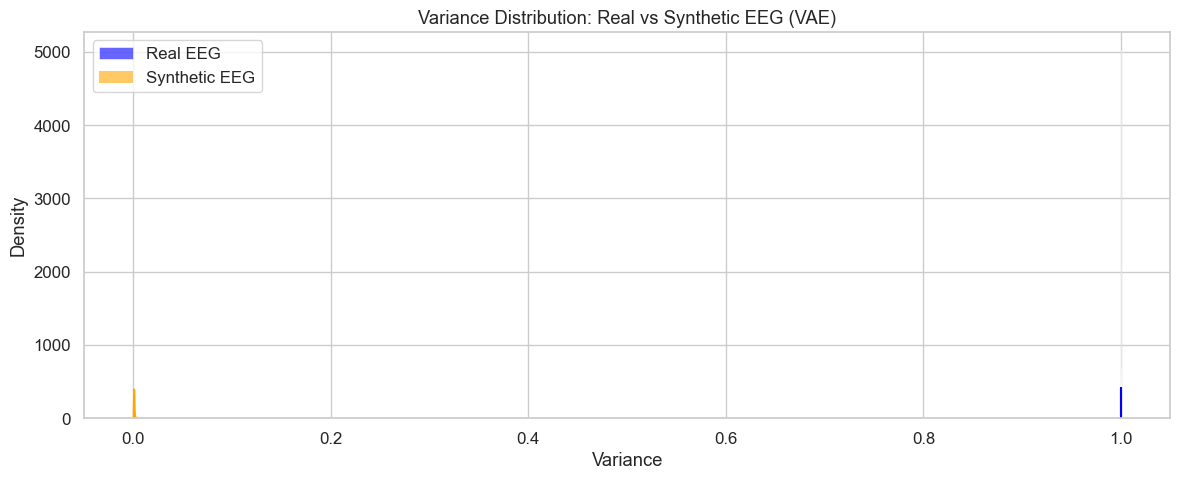

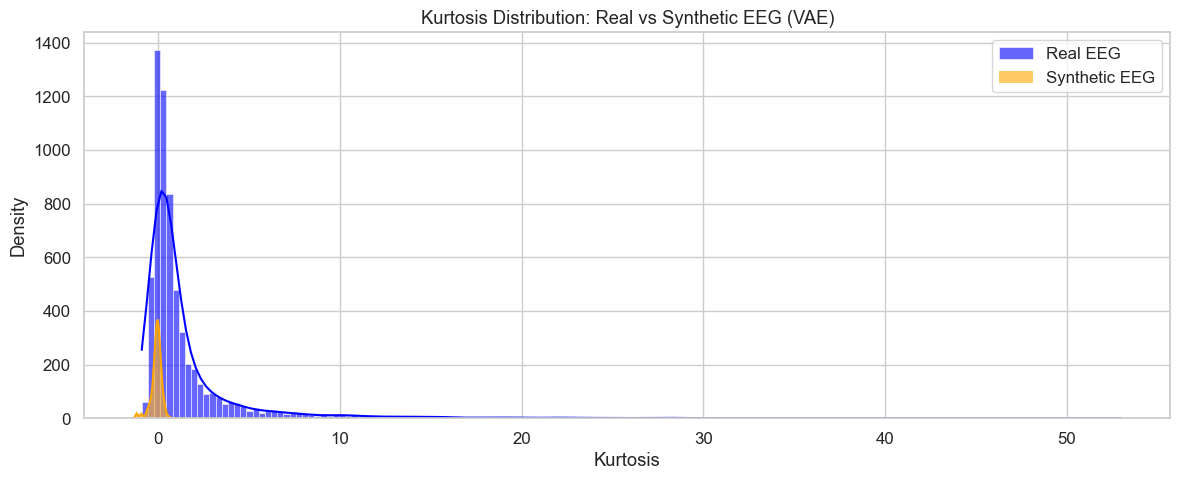

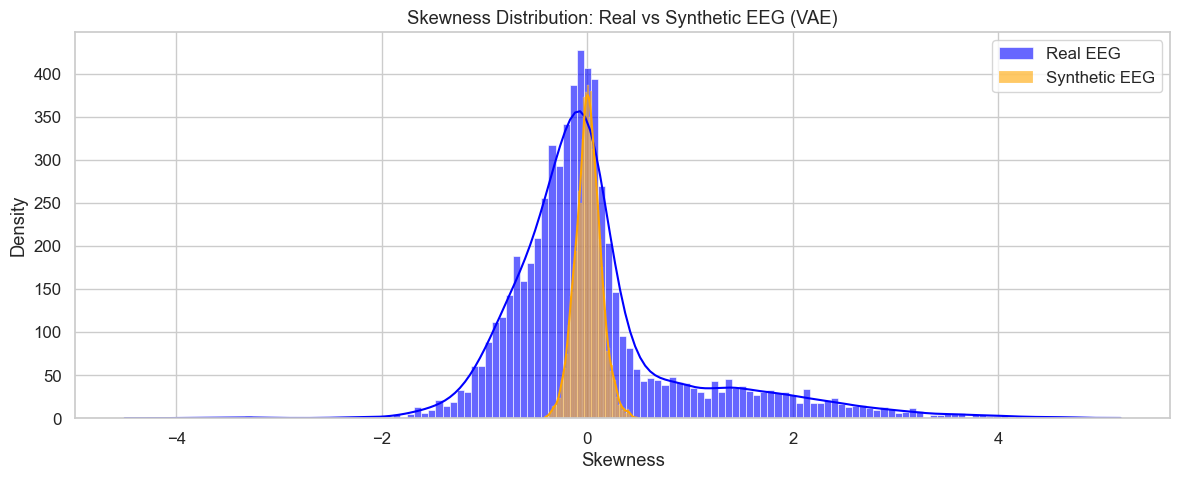

In [9]:
# Plot statistical comparisons using library function
fig_mean = plot_statistical_comparison(real_mean, synthetic_mean, "Mean", model_label="VAE")
plt.show()

fig_var = plot_statistical_comparison(real_var, synthetic_var, "Variance", model_label="VAE")
plt.show()

fig_kurt = plot_statistical_comparison(real_kurt, synthetic_kurt, "Kurtosis", model_label="VAE")
plt.show()

fig_skew = plot_statistical_comparison(real_skew, synthetic_skew, "Skewness", model_label="VAE")
plt.show()

### Analysis of Statistical Feature Distributions (Mean, Variance, Kurtosis, Skewness)
##### Mean and Variance : The distributions overlap but show clear differences in shape. The synthetic EEG data fails to accurately replicate the statistical properties of real EEG, particularly in the variance distribution where there's a complete absence of overlap between the two datasets.

##### In Kurtosis Distribution Plot, both distributions are somewhat similar. Synthetic EEG shows more spread with additional smaller peaks at lower kurtosis values.

##### In Skewness Distribution Plot, both distributions are centered which showed the distributions are fairly similar, though synthetic EEG shows slightly more spread

In general, this does signifies that our VAE model need more improvements.

### Time Domain Waveform

In [10]:
# Waveform visualization using library function
# Note: plot_waveforms is imported from generative_eeg_augmentation.plots

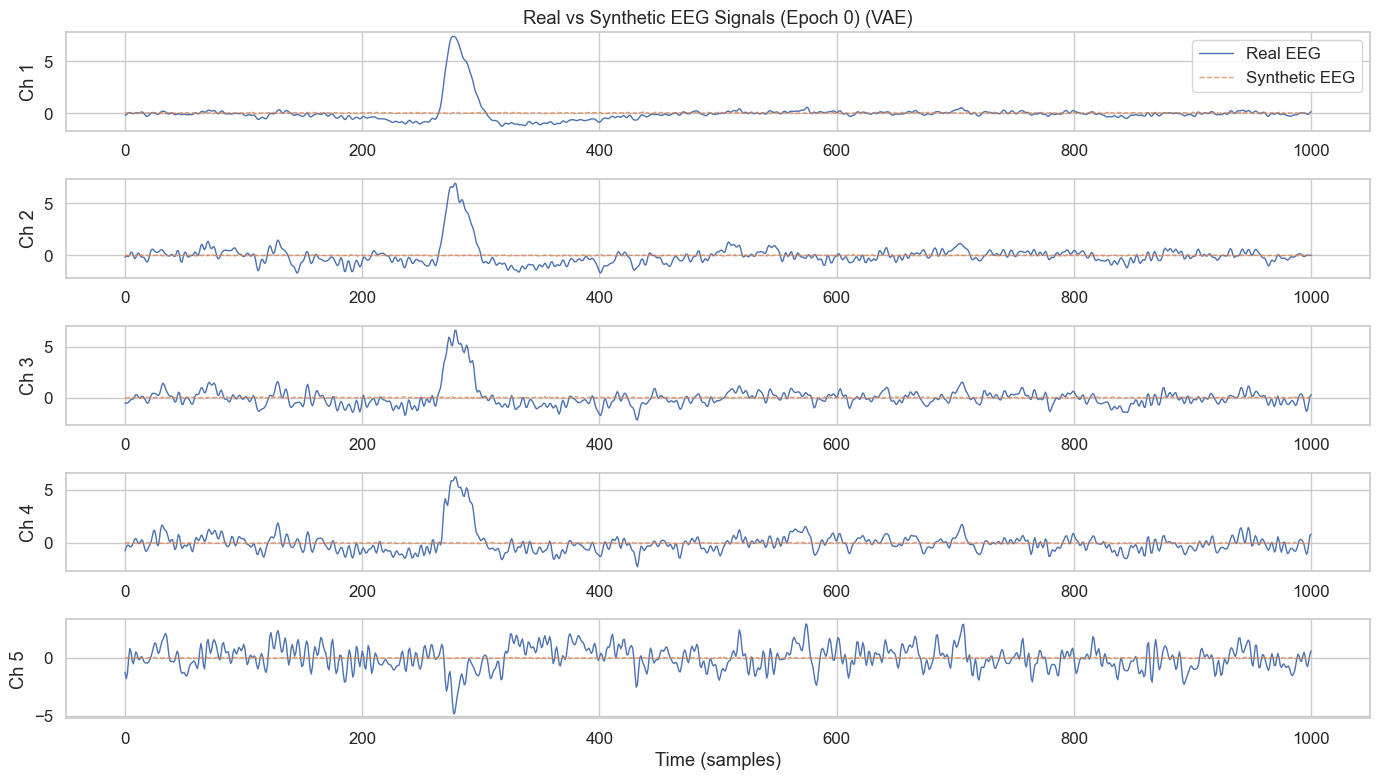

In [11]:
# Plot waveforms using library function
fig_waveforms = plot_waveforms(real_data_subset, synthetic_data, epoch_idx=0, channels=5, model_label="VAE")
plt.show()

### Analysis of Time-Domain Waveform Comparison (Epoch Visualization)

##### The real EEG signals (solid blue lines) and synthetic EEG signals (dashed orange lines) are plotted together for each channel.
##### The synthetic signals closely follow the overall waveform structure of the real EEG signals, indicating a good degree of similarity in temporal dynamics.
##### The alignment between the two signals is generally strong, but minor discrepancies are visible at certain points.
##### So, this plot demonstrates that the synthetic EEG signals closely mimic real EEG signals in terms of waveform structure and temporal dynamics

### Frequency-Domain Power Spectral Density (PSD) Curve

In [12]:
# Compute PSD using library function
# Note: compute_psd is imported from generative_eeg_augmentation.eval.eeg_metrics
real_psds, freqs = compute_psd(real_data_subset, sfreq=sfreq)
synthetic_psds, _ = compute_psd(torch.tensor(synthetic_data), sfreq=sfreq)

print(f"Computed PSDs with shape: {real_psds.shape}")

Computed PSDs with shape: (100, 63, 129)


In [13]:
# PSD visualization using library function
# Note: plot_psd_comparison is imported from generative_eeg_augmentation.plots

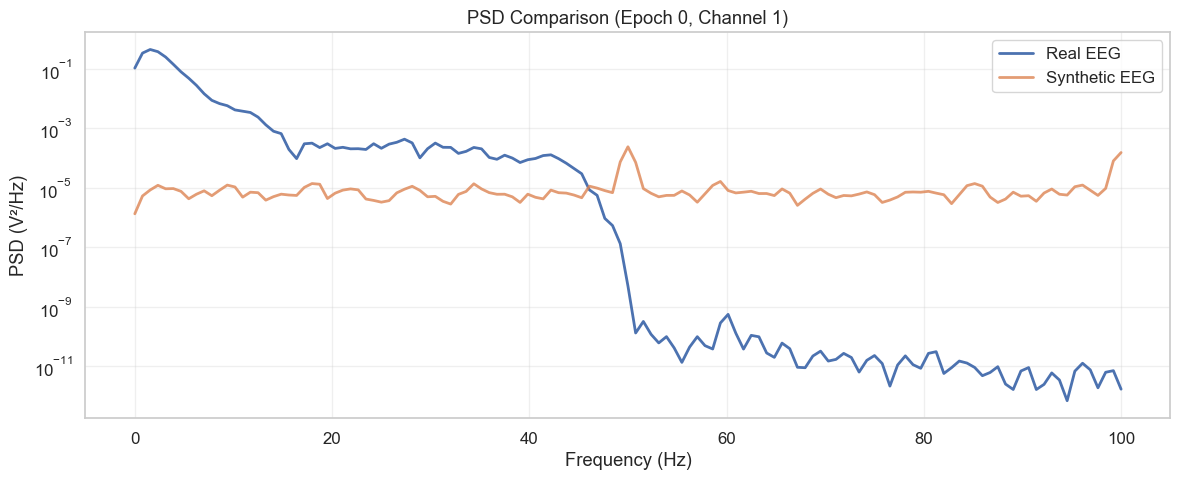

Plotted PSD Comparison (Epoch 0, Channel 1)


In [14]:
# Plot PSD comparison using library function
fig_psd = plot_psd_comparison(real_psds, synthetic_psds, freqs, epoch_idx=0, ch_idx=0)
plt.show()
print("Plotted PSD Comparison (Epoch 0, Channel 1)")

### Analysis of Frequency-Domain Power Spectral Density (PSD) Curve

##### The PSD curve for the real EEG signal (blue line) exhibits higher power across all frequencies compared to the synthetic EEG signal (orange line).
##### The synthetic PSD curve is significantly lower in magnitude, indicating a discrepancy in power distribution across frequencies.

##### So, this plot highlights a significant mismatch between real and synthetic EEG signals in terms of power spectral density. While the synthetic data may capture some temporal dynamics, it fails to replicate realistic frequency-domain characteristics accurately. This means that significant improvements are needed in modeling frequency-specific features of synthetic EEG data.

### Heatmap and Statistical Similarity

In [15]:
# Heatmap visualization using library function
# Note: plot_similarity_heatmap is imported from generative_eeg_augmentation.plots

In [16]:
# Feature labels
feature_labels = [
    'Real Mean', 'Real Variance', 'Real Kurtosis', 'Real Skewness',
    'Synthetic Mean', 'Synthetic Variance', 'Synthetic Kurtosis', 'Synthetic Skewness'
]

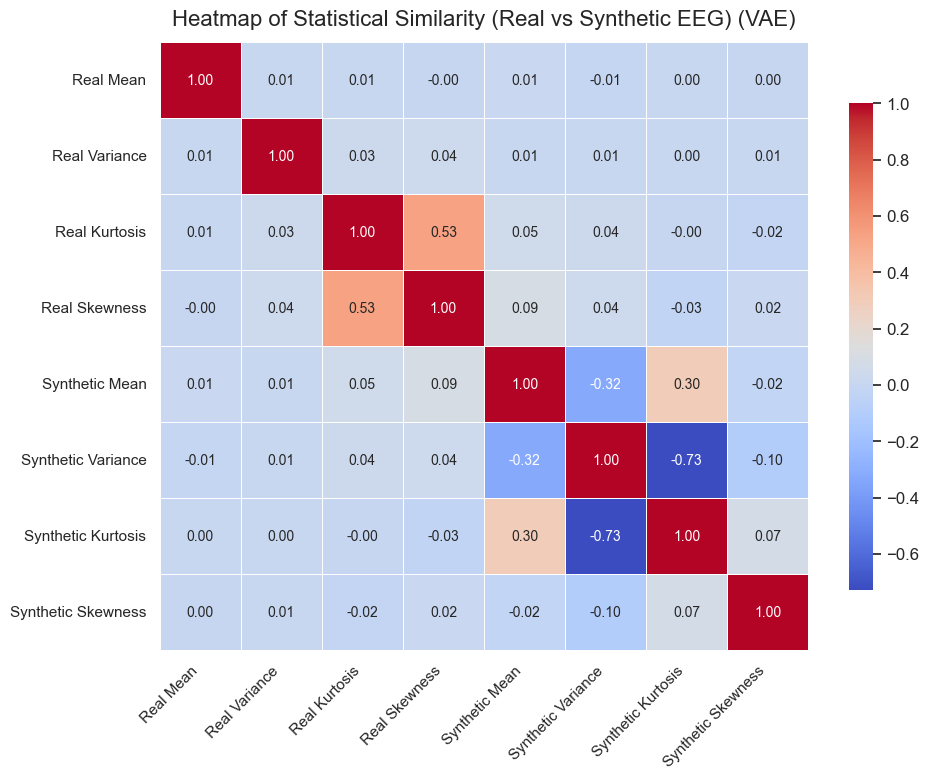

Plotted Heatmap of Statistical Similarity (Real vs Synthetic EEG)


In [17]:
# Flatten features for correlation analysis
real_feats = np.vstack([real_mean.flatten(), real_var.flatten(), real_kurt.flatten(), real_skew.flatten()])
synthetic_feats = np.vstack([synthetic_mean.flatten(), synthetic_var.flatten(), synthetic_kurt.flatten(), synthetic_skew.flatten()])

# Plot similarity heatmap using library function
fig_heatmap = plot_similarity_heatmap(real_feats, synthetic_feats, feature_labels, model_label="VAE")
plt.show()
print("Plotted Heatmap of Statistical Similarity (Real vs Synthetic EEG)")

### Analysis of Heatmap and Statistical Similarity

##### Real mean and variance show weak correlation.
##### Synthetic kurtosis exhibits a strong negative correlation with synthetic variance, indicating an imbalance in statistical features.

##### The heatmap reveals substantial differences between real and synthetic EEG signals across statistical metrics, particularly kurtosis and skewness.

### Summary
In Time-Domain Analysis, synthetic signals closely mimic real signals with minor inconsistencies but there is significant mismatches exist in power spectral density, particularly at higher frequencies.

Real and synthetic signals diverge substantially across statistical metrics like kurtosis and skewness.

These visualizations collectively highlight strengths in waveform structure replication but underscore areas for improvement in frequency-domain characteristics and statistical fidelity.





Overall, the visualizations provide valuable insights into the comparison between real and synthetic EEG signals. 
In the time-domain analysis, the synthetic signals do a good job of replicating the overall structure of real signals, with only minor inconsistencies observed. However, when examining the frequency-domain characteristics, there are notable mismatches, especially at higher frequencies, indicating room for improvement in capturing realistic power spectral density.

Additionally, the statistical analysis reveals significant differences between real and synthetic signals in metrics like kurtosis and skewness. These discrepancies highlight that while the waveform structure is fairly well replicated, deeper statistical properties and frequency-specific features need further refinement to achieve more accurate and realistic synthetic EEG data.